# k-Nearest Neighbors

Câu lạc bộ tin học muốn xếp một thành viên mới vào nhóm luyện phù hợp. Hai con số đã biết là điểm bài thuật toán và số giờ tự học mỗi tuần. Ta có thể nhìn những thành viên có hồ sơ gần giống rồi tham khảo nhóm của họ. Nhưng nếu đổi giờ thành phút, người mới có nên bị xếp sang nhóm khác? Bài này dùng k-Nearest Neighbors (kNN) để trả lời cả cách dự đoán lẫn câu hỏi tưởng như rất nhỏ về đơn vị đo.

> **Mục tiêu sau bài này**
>
> - Tự tìm láng giềng và tính một dự đoán phân loại hoặc hồi quy.
> - Giải thích ảnh hưởng của khoảng cách, thang đo, k và quy tắc phá hòa.
> - Dùng Pipeline để chọn k mà không làm lọt dữ liệu validation.

## Thuật toán

Cho tập huấn luyện $\{(\mathbf{x}_i, y_i)\}_{i=1}^n$ và một điểm cần dự đoán $\mathbf{q}$:

1. Tính khoảng cách $d(\mathbf{q}, \mathbf{x}_i)$ đến mọi điểm.
2. Lấy tập $N_k(\mathbf{q})$ gồm $k$ điểm gần nhất.
3. Phân loại: chọn nhãn xuất hiện nhiều nhất trong $N_k$. Hồi quy: lấy trung bình $y$ của $N_k$.

Biến thể có trọng số cho láng giềng càng gần càng có tiếng nói lớn, ví dụ trọng số $1/d$.

kNN là học lười (lazy learning): “huấn luyện” chỉ là cất dữ liệu đi, mọi công việc dồn vào lúc dự đoán. Ngược lại, mô hình tuyến tính là học chăm (eager): học xong chỉ giữ $\mathbf{w}$, dữ liệu gốc có thể bỏ.

**Hỏi nhanh.** Có ba láng giềng: một láng giềng nhãn 0 ở khoảng cách 1, hai láng giềng nhãn 1 ở khoảng cách 4 và 5. Bỏ phiếu đều thì ra nhãn nào? Bỏ phiếu theo trọng số $1/d$ thì ra nhãn nào?

- A. Bỏ phiếu đều ra 0, trọng số $1/d$ ra 1
- B. Bỏ phiếu đều ra 1, trọng số $1/d$ ra 0
- C. Cả hai cách đều ra nhãn 1
- D. Cả hai cách đều ra nhãn 0

<details><summary>Đáp án</summary>

B. Bỏ phiếu đều ra 1, trọng số $1/d$ ra 0

Bỏ phiếu đều thì nhãn 1 có hai phiếu và thắng. Theo trọng số $1/d$, nhãn 0 được 1 điểm, còn nhãn 1 chỉ được $0.25 + 0.2 = 0.45$. Một láng giềng rất gần có thể thắng hai láng giềng ở xa. Chọn kiểu trọng số nào cũng là một hyperparameter.

</details>

## Khoảng cách

| Tên | Công thức | Hợp với |
|---|---|---|
| Euclid (L2) | $\sqrt{\sum_j (q_j - x_j)^2}$ | Đặc trưng số đã chuẩn hóa |
| Manhattan (L1) | $\sum_j \lvert q_j - x_j\rvert$ | Ít nhạy với một chiều lệch lớn |
| Cosine | $1 - \dfrac{\mathbf{q}^\top\mathbf{x}}{\lVert\mathbf{q}\rVert\,\lVert\mathbf{x}\rVert}$ | Embedding, văn bản: quan tâm hướng, không quan tâm độ dài |

Với vector đã chuẩn hóa về độ dài 1, $\lVert\mathbf{q} - \mathbf{x}\rVert^2 = 2 - 2\cos(\mathbf{q}, \mathbf{x})$, nên xếp hạng theo Euclid và theo cosine là như nhau. Thư viện tìm kiếm embedding dùng đúng mẹo này.



**Hỏi nhanh.** Văn bản A là văn bản B chép lại hai lần, nên vector đếm từ của A đúng bằng 2 lần vector của B. Theo cosine và theo Euclid, A và B có gần nhau không?

- A. Cả hai khoảng cách đều bằng 0
- B. Khoảng cách cosine lớn, Euclid bằng 0
- C. Cả hai khoảng cách đều lớn
- D. Khoảng cách cosine bằng 0, Euclid khá lớn

<details><summary>Đáp án</summary>

D. Khoảng cách cosine bằng 0, Euclid khá lớn

Hai vector cùng hướng nên khoảng cách cosine bằng 0. Khoảng cách Euclid thì đúng bằng độ dài của B, lớn khi B dài. Với văn bản, độ dài thường không phải thứ cần so, nên người ta dùng cosine hoặc chuẩn hóa độ dài trước.

</details>

**Thang đo quyết định tất cả.** Hai đặc trưng “tuổi” (20 đến 60) và “thu nhập tháng” tính bằng đồng (5 triệu đến 50 triệu): khoảng cách gần như chỉ còn là chênh lệch thu nhập, tuổi chẳng còn tiếng nói nào. Khi đơn vị các cột không so sánh được, chuẩn hóa hoặc thiết kế trọng số khoảng cách là bước cần kiểm bằng validation.

## Chọn k

- $k = 1$: lỗi trên train thường bằng 0 nếu không có hồ sơ trùng nhau mang nhãn mâu thuẫn, ranh giới lởm chởm theo từng điểm nhiễu. Variance cao.
- $k$ lớn: ranh giới mượt, nhưng $k = n$ thì đoán mọi điểm là lớp đông nhất. Bias cao.

Chọn $k$ bằng cross-validation. Với phân loại nhị phân, $k$ lẻ tránh hòa phiếu.

**Hỏi nhanh.** Một bạn chọn $k = 1$, vì trong các $k$ đã thử, $k = 1$ có lỗi train thấp nhất, bằng 0. Chọn như vậy có ổn không?

- A. Ổn, vì lỗi train bằng 0 là tốt nhất có thể
- B. Ổn, nếu trong train không có điểm nào trùng nhau
- C. Không ổn, phải chọn $k$ lớn nhất đã thử cho an toàn
- D. Không ổn, vì 1-NN luôn khớp train do mỗi điểm tự là láng giềng của nó

<details><summary>Đáp án</summary>

D. Không ổn, vì 1-NN luôn khớp train do mỗi điểm tự là láng giềng của nó

Mỗi điểm train là láng giềng gần nhất của chính nó, nên 1-NN gần như lúc nào cũng có lỗi train bằng 0. Lỗi train vì vậy không nói gì về điểm mới. Ta chọn $k$ bằng lỗi validation hoặc cross-validation. Chọn $k$ lớn nhất cũng chưa chắc tốt, vì ranh giới có thể bị làm mượt quá tay.
Phỏng theo: [CMU 10-601 · Exam 1 Practice · Q2.3(f)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam1_practice_problems.pdf#page=12)

</details>



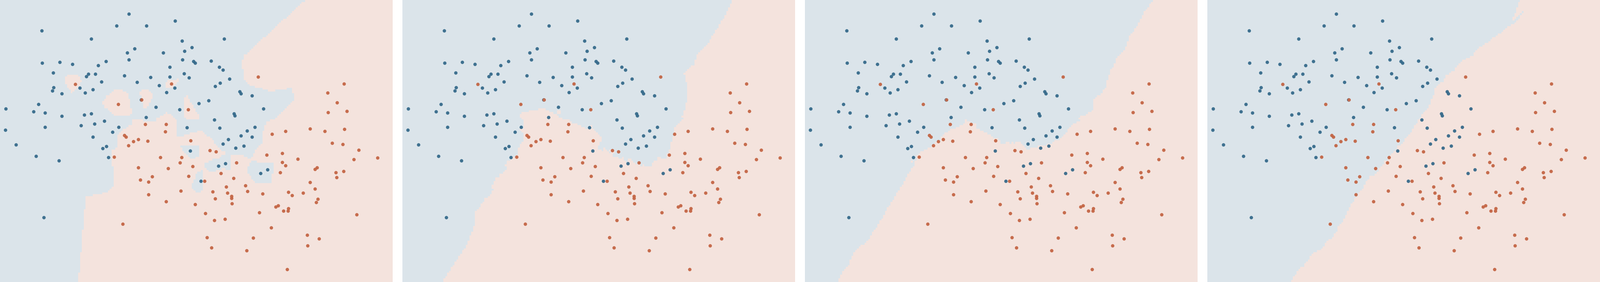

Cover và Hart (1967) chứng minh rằng khi số mẫu tiến tới vô hạn, lỗi của 1-NN không vượt quá hai lần lỗi Bayes, mức lỗi nhỏ nhất mà mọi bộ phân loại có thể đạt. Đó là kết quả tiệm cận: với vài trăm mẫu trong một bài thi, nó không hứa gì, và $k$ vẫn phải chọn bằng validation.

## Lời nguyền số chiều

Khi số chiều tăng, với dữ liệu trải đều, điểm gần nhất và điểm xa nhất cách truy vấn gần bằng nhau, nên “láng giềng” mất ý nghĩa. Dữ liệu thật thường nằm gần một cấu trúc ít chiều hơn nhiều, nên mức độ tệ còn tùy số chiều thực chất của nó. Một phép tính nhỏ cho thấy hiện tượng này. Dữ liệu rải đều trong khối lập phương đơn vị $d$ chiều. Muốn một khối lập phương nhỏ chứa 10% dữ liệu thì cạnh của nó phải dài $0.1^{1/d}$:

- $d = 1$: cạnh $0.1$, đúng là “lân cận”.
- $d = 10$: cạnh $0.79$, gần hết cả khoảng.
- $d = 100$: cạnh $0.98$.



Láng giềng gần nhất trong 100 chiều thực chất chẳng gần chút nào. Vì vậy kNN chạy tốt trên đặc trưng ít chiều, hoặc trên embedding mà mô hình đã học sẵn để những thứ giống nhau nằm gần nhau, thường kèm giảm chiều bằng PCA (bài 2.9).

**Hỏi nhanh.** Dữ liệu rải đều trong một khối lập phương đơn vị 50 chiều. Một khối lập phương nhỏ chứa 1% dữ liệu thì có cạnh dài khoảng bao nhiêu?

- A. $0.02$
- B. $0.2$
- C. $0.91$
- D. $0.99$

<details><summary>Đáp án</summary>

C. $0.91$

Cạnh bằng $0.01^{1/50} = e^{\ln 0.01/50} \approx e^{-0.092} \approx 0.91$. Muốn lấy chỉ 1% dữ liệu mà vẫn phải đi gần hết chiều dài mỗi trục. Nói cách khác, “vùng lân cận” đã gần bằng cả miền.

</details>

## Chi phí

Dự đoán một điểm tốn $O(nd)$. Với $n$ lớn, có ba cách tăng tốc:

- Cây không gian (KD-tree, Ball tree): nhanh khi $d$ nhỏ, dưới khoảng 20.
- Vector hóa bằng phép nhân ma trận trên GPU: tính một lần khoảng cách giữa cả lô truy vấn và cả tập dữ liệu.
- Tìm gần đúng (approximate nearest neighbor) như FAISS, HNSW: chấp nhận đôi khi sót láng giềng thật để nhanh hơn hàng trăm lần. Đây là nền của các hệ thống tìm kiếm ảnh và văn bản.

Brute force cho một truy vấn tính $n$ khoảng cách trong $O(nd)$, rồi chọn $k$ phần tử: sort toàn bộ là $O(n \log n)$, còn `argpartition` chọn trước rồi chỉ sort $k$ phần tử thường rẻ hơn. Với $m$ truy vấn, ma trận khoảng cách $m \times n$ có thể hết RAM dù code chỉ một dòng; chia truy vấn thành batch là cách sửa đầu tiên. KD-tree không bảo đảm $O(\log n)$ cho mọi dữ liệu: ở nhiều chiều nó có thể phải duyệt gần hết cây.

**Hỏi nhanh.** Cần tìm ảnh giống nhau trong 1 triệu ảnh, mỗi ảnh là một embedding 512 chiều, và mỗi truy vấn phải trả lời trong vài mili giây. Cách nào hợp lý?

- A. KD-tree, vì nó luôn bảo đảm $O(\log n)$ mỗi truy vấn
- B. Giảm $k$ xuống 1 để mỗi truy vấn tính ít khoảng cách hơn
- C. Duyệt hết bằng vòng `for` Python qua từng ảnh
- D. Tìm gần đúng (HNSW, FAISS), chấp nhận đôi khi sót

<details><summary>Đáp án</summary>

D. Tìm gần đúng (HNSW, FAISS), chấp nhận đôi khi sót

Ở 512 chiều, KD-tree gần như phải duyệt cả cây. Giảm $k$ cũng không bớt được phép tính khoảng cách nào. Duyệt hết bằng vòng `for` Python tốn cỡ $5\cdot 10^8$ phép tính cho mỗi truy vấn. Tìm gần đúng đổi một chút độ chính xác lấy tốc độ, đúng thứ ta cần ở đây.

</details>

## Ví dụ tính tay

Dữ liệu: $A(1, 1)$ nhãn đỏ, $B(2, 1)$ đỏ, $C(4, 3)$ xanh, $D(5, 4)$ xanh, $E(3, 2)$ xanh. Truy vấn $\mathbf{q} = (2, 2)$, $k = 3$, khoảng cách Euclid bình phương:

| Điểm | A | B | C | D | E |
|---|---|---|---|---|---|
| $d^2$ | 2 | 1 | 5 | 13 | 1 |

Ba láng giềng gần nhất là $B$, $E$, $A$: hai đỏ, một xanh, nên dự đoán đỏ. Với $k = 1$ thì $B$ và $E$ cùng khoảng cách: cần quy tắc phá hòa, chẳng hạn chọn điểm có chỉ số nhỏ hơn. Đề chấm tự động thường ghi rõ quy tắc phá hòa; đọc sót nó là đủ để kết quả lệch đáp án.



## Từ ví dụ tay đến code

Trong ví dụ năm điểm vừa tính, ta chưa cần thư viện. Mỗi hàng là một hồ sơ, hai cột là hai đặc trưng. Trừ truy vấn khỏi từng hàng bằng broadcasting, bình phương từng độ lệch, rồi cộng theo `axis=1` để được một khoảng cách cho mỗi hàng. Không lấy căn vì căn bậc hai tăng theo đối số: xếp hạng khoảng cách bình phương cho cùng thứ tự, tránh thêm một phép tính.

In [ ]:
import numpy as np

points = np.array([[1, 1], [2, 1], [4, 3], [5, 4], [3, 2]], dtype=float)
labels = np.array([0, 0, 1, 1, 1])
query = np.array([2, 2], dtype=float)
distance2 = np.sum((points - query) ** 2, axis=1)
order = np.argsort(distance2, kind="stable")
neighbors = order[:3]
counts = np.bincount(labels[neighbors], minlength=2)
print(distance2.astype(int).tolist())
print(neighbors.tolist(), counts.tolist(), int(np.argmax(counts)))
assert neighbors.tolist() == [1, 4, 0]

[2, 1, 5, 13, 1]
[1, 4, 0] [2, 1] 0


Chỉ số trong code bắt đầu từ 0, nên `[1, 4, 0]` chính là B, E, A. `stable` giữ thứ tự ban đầu khi khoảng cách bằng nhau; `argmax` chọn nhãn có chỉ số nhỏ nhất khi số phiếu hòa. Đây là hai quy tắc của **bản cài này**, không phải quy tắc chung của mọi thư viện. Với `k=1`, đổi thứ tự dữ liệu có thể đổi dự đoán ở điểm hòa khoảng cách. Trong đề chấm chính xác, phải cài quy ước đề yêu cầu.

**Hỏi nhanh.** Vì sao không cần lấy căn của `distance2` trước khi sắp xếp?

- A. Vì khoảng cách Euclid vốn không có căn
- B. Vì căn bậc hai giữ nguyên thứ tự của các số không âm
- C. Vì khoảng cách bình phương bằng khoảng cách Euclid
- D. Vì `argsort` không chạy được trên số thực

<details><summary>Đáp án</summary>

B. Vì căn bậc hai giữ nguyên thứ tự của các số không âm

Ta chỉ cần thứ tự để chọn láng giềng, và căn bậc hai không làm đổi thứ tự ấy. Nhưng nếu dùng trọng số $1/d$ thì lại cần khoảng cách $d$ thật, không được âm thầm thay bằng $d^2$.

</details>

## Thang đo thay đổi người hàng xóm

Xét hồ sơ truy vấn `(8 điểm, 5 giờ)`, hai hồ sơ A `(9, 5)` và B `(8, 6)`. Trong đơn vị hiện tại cả hai cách truy vấn 1. Nếu đổi giờ thành phút, B cách 60 còn A vẫn cách 1; thông tin thực tế không đổi mà thuật toán đã thiên hẳn về A. Hình dưới cho thấy đổi đơn vị kéo một trục dài ra. StandardScaler là một cách đưa các cột về thang so sánh được; còn nếu biết một cột quan trọng hơn, ta có thể dùng trọng số có chủ đích và kiểm bằng validation.



Cần phân biệt chuẩn hóa **theo cột** với chuẩn hóa **độ dài từng vector**. StandardScaler thường dùng cho các đặc trưng số khác đơn vị. Với embedding dùng cosine, ta thường chia mỗi hàng cho norm của chính hàng đó. Vector toàn 0 không có hướng, nên cosine chưa xác định; cần quy tắc xử lý riêng trước khi tính.

**Hỏi nhanh.** Mỗi ảnh là một embedding 512 chiều, và ta tìm ảnh giống nhau bằng cosine. Muốn chạy kNN theo Euclid cho nhanh, ta chuẩn hóa thế nào?

- A. Dùng `StandardScaler` theo từng cột của bảng embedding
- B. Chia mỗi hàng cho độ dài (norm) của chính nó
- C. Đưa từng cột về đoạn $[0, 1]$ theo min và max
- D. Không cần, vì Euclid và cosine luôn xếp hạng như nhau

<details><summary>Đáp án</summary>

B. Chia mỗi hàng cho độ dài (norm) của chính nó

Khi mỗi hàng có độ dài 1 thì $\lVert\mathbf q-\mathbf x\rVert^2 = 2 - 2\cos$, nên Euclid xếp hạng y như cosine. Chuẩn hóa theo cột thì đổi hướng của các vector, tức đổi chính đại lượng mà cosine đang đo. Không chuẩn hóa thì hai cách xếp hạng chỉ trùng nhau khi mọi vector có cùng độ dài.

</details>

## Dùng thư viện

In [ ]:
from sklearn.datasets import load_wine
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = load_wine(return_X_y=True)
for scale in [False, True]:
    steps = [StandardScaler()] if scale else []
    model = make_pipeline(*steps, KNeighborsClassifier())
    grid = GridSearchCV(model, {"kneighborsclassifier__n_neighbors": [1, 3, 5, 9, 15]}, cv=5)
    grid.fit(X, y)
    print("chuẩn hóa" if scale else "không chuẩn hóa", round(grid.best_score_, 3), grid.best_params_)

không chuẩn hóa 0.725 {'kneighborsclassifier__n_neighbors': 1}
chuẩn hóa 0.966 {'kneighborsclassifier__n_neighbors': 9}


Chênh lệch lớn có lý do cụ thể: cột proline chạy từ 278 đến 1680, trong khi phần lớn các cột khác chỉ cỡ 0.1 đến 30. Chưa chuẩn hóa, proline chiếm khoảng 99.8% bình phương khoảng cách, nên kNN gần như chỉ so một cột và phải dùng $k=1$ để vớt vát.



**Hỏi nhanh.** Trong bộ wine chưa chuẩn hóa, riêng cột proline chiếm khoảng 99.8% bình phương khoảng cách. Thêm một feature hữu ích nằm trong khoảng $[0, 1]$, thì kNN với khoảng cách thô sẽ ra sao?

- A. Gần như không đổi, vì feature mới gần như vô hình
- B. Tốt hơn hẳn, vì có thêm thông tin
- C. Tệ hơn hẳn, vì thêm một chiều nữa
- D. Không chạy được, vì các cột khác thang đo

<details><summary>Đáp án</summary>

A. Gần như không đổi, vì feature mới gần như vô hình

Độ lệch của feature mới tối đa là 1, bình phương tối đa cũng là 1, trong khi độ lệch của proline cỡ hàng trăm. Khoảng cách thô gần như không nhìn thấy feature mới. Vì vậy chuẩn hóa phải nằm trong Pipeline, trước khi thử feature hay dò $k$.

</details>

## Bẫy cần kiểm

> **Đọc đúng điều kiện**
>
> Một k lẻ chỉ tránh hòa số phiếu khi có đúng hai lớp và phiếu đồng trọng số. Ba lớp với k=3 vẫn có thể hòa 1–1–1. Điểm train của 1-NN cũng không nhất thiết bằng 1 nếu có hai hồ sơ trùng nhau mang nhãn khác. Không có validation độc lập thì `best_score_` chỉ là điểm dùng để chọn cấu hình, chưa phải điểm tổng quát cuối cùng.

**Hỏi nhanh.** Đổi cột thu nhập từ triệu đồng sang đồng, và vẫn dùng khoảng cách thô. Chuyện gì xảy ra?

- A. Không đổi gì, vì vẫn là cùng một thông tin
- B. Cột thu nhập lấn át hẳn các cột khác
- C. Các cột khác được coi trọng hơn
- D. Phải tăng $k$ theo cùng hệ số

<details><summary>Đáp án</summary>

B. Cột thu nhập lấn át hẳn các cột khác

Độ lệch của cột ấy nhân lên một triệu lần, và trong bình phương khoảng cách thì nhân $10^{12}$ lần. Các cột khác gần như mất hết tiếng nói. Còn $k$ thì không liên quan đến thang đo.

</details>

## Khi đi thi

- **Có embedding là có baseline.** Ảnh, văn bản, âm thanh: trích embedding từ model pretrained (Phase 4), chuẩn hóa độ dài, rồi kNN theo cosine. Bài dạng tìm kiếm hay ghép cặp thường bắt đầu bằng đúng bước này.
- **Đặc trưng từ láng giềng.** Trung bình nhãn của $k$ láng giềng là đặc trưng rất mạnh cho gradient boosting, nhưng phải tính out-of-fold để không rò rỉ nhãn của chính mẫu đó.
- **Đọc kỹ quy tắc phá hòa và kiểu khoảng cách** trong đề.
- **Không dùng kNN thô** trên hàng trăm đặc trưng số chưa chọn lọc: chuẩn hóa, chọn feature hoặc giảm chiều trong Pipeline trước.
- **Đề bắt buộc dùng kNN** thì phần lớn công sức nằm ở tiền xử lý và khoảng cách, không phải ở $k$.

## Tóm tắt

- kNN dự đoán theo $k$ điểm gần nhất; không có giai đoạn học tham số.
- Chuẩn hóa đặc trưng và chọn khoảng cách đúng quan trọng hơn chọn $k$.
- $k$ nhỏ thì variance cao, $k$ lớn thì bias cao; chọn bằng cross-validation.
- Nhiều chiều thì “gần” mất nghĩa; kNN mạnh nhất trên embedding tốt.


## Kiểm tra cuối bài

Mười câu kiểm cả cách hiểu, phép tính và quy trình. Câu sai chỉ ra phần cần đọc lại; hãy làm trước khi mở lời giải.

**Câu 1.** Năm láng giềng có nhãn `[1, 0, 0, 1, 0]`, bỏ phiếu đều. Nhãn dự đoán là gì, và xác suất lớp 1 tính theo tỉ lệ láng giềng là bao nhiêu?

- A. Nhãn 0, xác suất 0.4
- B. Nhãn 1, xác suất 0.4
- C. Nhãn 0, xác suất 0.6
- D. Nhãn 1, xác suất 0.6

<details><summary>Đáp án</summary>

A. Nhãn 0, xác suất 0.4

Lớp 0 có 3 phiếu, lớp 1 có 2 phiếu, nên dự đoán là lớp 0. Xác suất lớp 1 theo tỉ lệ phiếu là $2/5 = 0.4$.

</details>
**Câu 2.** Câu nào về kNN **luôn** đúng?

- A. Giảm $k$ làm ranh giới quyết định đơn giản hơn
- B. kNN chỉ dùng cho phân loại, không dùng cho hồi quy
- C. Tăng $k$ làm mô hình ít nhạy với điểm ngoại lai
- D. kNN chỉ dùng được với feature là số thực

<details><summary>Đáp án</summary>

C. Tăng $k$ làm mô hình ít nhạy với điểm ngoại lai

Giảm $k$ làm ranh giới gấp khúc theo từng điểm, tức phức tạp hơn. Tăng $k$ thì một điểm lạ chỉ còn là một phiếu giữa nhiều phiếu. Hồi quy thì lấy trung bình của các láng giềng. Feature dạng danh mục vẫn dùng được, với một khoảng cách phù hợp như Hamming, hoặc sau khi mã hóa.
Phỏng theo: [CMU 10-601 · Exam 1 Practice · Q2.4](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam1_practice_problems.pdf#page=13)

</details>
**Câu 3.** Hai láng giềng có khoảng cách $d_1 = 1$ và $d_2 = 2$, target lần lượt là 0 và 6. Nếu trọng số là $1/d$, dự đoán hồi quy bằng bao nhiêu?

- A. 2
- B. 3
- C. 1.2
- D. 6

<details><summary>Đáp án</summary>

A. 2

Trung bình có trọng số là $(1\cdot 0 + 0.5\cdot 6)/(1 + 0.5) = 2$. Ra 3 là bỏ qua trọng số. Ra 1.2 là dùng nhầm $1/d^2$.

</details>
**Câu 4.** Dữ liệu một chiều, $n$ điểm đã sắp xếp, phân loại hai lớp bằng 1-NN với khoảng cách Euclid. Có dựng được một quy tắc chỉ gồm các phép so sánh dạng $x \ge t$, nối tiếp nhau, mà cho dự đoán giống hệt 1-NN trên mọi đầu vào không?

- A. Được, đặt ngưỡng ở trung điểm của hai điểm kề nhau khác nhãn
- B. Không được, vì so sánh từng ngưỡng không bắt chước được khoảng cách
- C. Chỉ được khi các điểm train cách đều nhau trên trục
- D. Chỉ được nếu dùng $k$ lẻ thay vì $k = 1$

<details><summary>Đáp án</summary>

A. Được, đặt ngưỡng ở trung điểm của hai điểm kề nhau khác nhãn

Trên một trục, mỗi điểm “sở hữu” đoạn từ trung điểm với láng giềng bên trái tới trung điểm với láng giềng bên phải. Nhãn chỉ đổi ở trung điểm giữa hai điểm kề nhau khác nhãn. Vì vậy đặt các ngưỡng đúng tại những trung điểm ấy là cho cùng dự đoán, bỏ qua quy ước tại chính trung điểm. Bài 2.5 sẽ gọi quy tắc kiểu này là cây quyết định.
Phỏng theo: [CMU 10-601 · Exam 1 Practice · Q2.5](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam1_practice_problems.pdf#page=13)

</details>
**Câu 5.** Một kNN dùng `StandardScaler` fit trên train. Đổi cột thu nhập từ triệu đồng sang đồng ở cả train lẫn validation, rồi fit lại scaler đúng trên train. Bỏ qua sai số làm tròn, khoảng cách sau chuẩn hóa thay đổi thế nào?

- A. Không đổi, vì mean và std cũng đổi theo đơn vị
- B. Cột thu nhập vẫn lớn hơn 1 000 000 lần
- C. Khoảng cách ở mọi cột giảm 1 000 000 lần
- D. Chỉ không đổi khi scaler fit cả trên validation

<details><summary>Đáp án</summary>

A. Không đổi, vì mean và std cũng đổi theo đơn vị

Với hệ số đổi đơn vị dương $a$, ta có $(ax - a\mu)/(a\sigma) = (x - \mu)/\sigma$. Đây chính là tác dụng của chuẩn hóa, khác với tình huống dùng khoảng cách thô ở câu hỏi nhanh.

</details>
**Câu 6.** Đề phân loại hai lớp, 30 feature số, chấm bằng macro-F1. Đề **bắt buộc** kNN là mô hình học có giám sát duy nhất, còn tiền xử lý thì tùy ý. Hướng làm nào hợp lý nhất?

- A. Chỉ dò thật kỹ $k$, vì $k$ là tham số duy nhất của kNN
- B. Học một mô hình khác như boosting trước, rồi lấy dự đoán của nó làm feature cho kNN
- C. Chuẩn hóa, chọn feature trong Pipeline, rồi dùng cross-validation theo macro-F1
- D. Fit `StandardScaler` trên cả train lẫn test cho cùng thang

<details><summary>Đáp án</summary>

C. Chuẩn hóa, chọn feature trong Pipeline, rồi dùng cross-validation theo macro-F1

Với kNN, khoảng cách quyết định gần như tất cả, nên chuẩn hóa và chọn feature đáng công hơn dò $k$. Mọi bước học từ dữ liệu nằm trong Pipeline và được chọn bằng cross-validation theo đúng metric của đề. Lấy dự đoán của một mô hình có giám sát khác làm feature là trái luật đề. Còn test ẩn thì không được tham gia fit scaler.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Problem 9](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=22)

</details>
**Câu 7.** $k = 3$, ba láng giềng gần nhất mang ba nhãn khác nhau A, B, C, bỏ phiếu đều. Trước khi áp quy tắc xử lý hòa của thư viện, kết quả là gì?

- A. A thắng, vì là láng giềng gần nhất
- B. C thắng, vì đứng cuối danh sách
- C. Không thể hòa, vì $k$ là số lẻ
- D. Hòa 1–1–1, $k$ lẻ cũng không tránh được

<details><summary>Đáp án</summary>

D. Hòa 1–1–1, $k$ lẻ cũng không tránh được

$k$ lẻ chỉ tránh được hòa khi có đúng hai lớp và bỏ phiếu đều. Có ba lớp thì 1–1–1 vẫn xảy ra, nên ta phải biết thư viện đang phá hòa theo cách nào.

</details>
**Câu 8.** Hai vector đơn vị $\mathbf u$, $\mathbf v$ có cosine bằng 0.5. Bình phương khoảng cách Euclid giữa chúng bằng bao nhiêu?

- A. 0.5
- B. 1
- C. 2
- D. 4

<details><summary>Đáp án</summary>

B. 1

$\lVert\mathbf u - \mathbf v\rVert^2 = 2 - 2\cdot 0.5 = 1$.

</details>
**Câu 9.** Có 10 000 truy vấn và 10 000 điểm tham chiếu. Ma trận khoảng cách kiểu `float64` tốn bao nhiêu byte?

- A. $8\times 10^6$
- B. $8\times 10^7$
- C. $8\times 10^8$
- D. $8\times 10^{10}$

<details><summary>Đáp án</summary>

C. $8\times 10^8$

Ma trận có $10^4 \times 10^4 = 10^8$ phần tử, mỗi phần tử `float64` chiếm 8 byte, nên cần $8\times 10^8$ byte, khoảng 800 MB. Với cỡ này vẫn nên chia thành từng đợt nhỏ thay vì tạo cả ma trận một lúc.

</details>
**Câu 10.** Trên cùng các fold, $k$ = 1, 5, 21 cho accuracy trên validation lần lượt là 0.76, 0.84 và 0.79. Chỉ chọn trong ba giá trị này thì chọn gì?

- A. $k = 21$, vì lấy trung bình nhiều mẫu luôn tốt hơn
- B. $k = 1$, vì không làm mờ cấu trúc cục bộ
- C. $k = 5$, vì cao nhất trong những giá trị đã thử
- D. Nội suy accuracy rồi chọn $k = 13$, không cần chấm

<details><summary>Đáp án</summary>

C. $k = 5$, vì cao nhất trong những giá trị đã thử

$k = 5$ có điểm cao nhất trong ba giá trị đã thử, và tăng $k$ không làm điểm tăng đều trên dữ liệu này. Muốn biết $k = 13$ ra sao thì phải chấm thật, không suy ra bằng nội suy được.

</details>
## Đọc thêm

- James, Witten, Hastie, Tibshirani — [*An Introduction to Statistical Learning*](https://www.statlearning.com/), chương 2 và 4. kNN đặt cạnh các bộ phân loại khác, với lập luận bias–variance khi chọn $k$.
- Cover, Hart (1967) — *Nearest Neighbor Pattern Classification*, IEEE Transactions on Information Theory. Bài báo gốc của cận hai lần lỗi Bayes.
- [scikit-learn — Nearest Neighbors](https://scikit-learn.org/stable/modules/neighbors.html). So sánh metric, brute force, KD-tree và Ball tree; chú ý phần chi phí theo số chiều.
- [ISLP — Classification lab](https://intro-stat-learning.github.io/ISLP/labs/Ch04-classification-lab.html). Đối chiếu kNN với mô hình xác suất và thực hành lựa chọn k.